In [2]:
%%writefile ../src/features.py
"""Feature engineering shared by training, API and simulator."""

import numpy as np
import pandas as pd

# Original dataset column name -> short name
RENAME = {
    "Air temperature [K]": "air_temp",
    "Process temperature [K]": "process_temp",
    "Rotational speed [rpm]": "rpm",
    "Torque [Nm]": "torque",
    "Tool wear [min]": "tool_wear",
}

RAW_SIGNALS = ["air_temp", "process_temp", "rpm", "torque", "tool_wear"]

FEATURE_COLUMNS = RAW_SIGNALS + [
    "power_w", "temp_diff", "wear_torque", "type_M", "type_H",
]


def engineer_features(df: pd.DataFrame) -> pd.DataFrame:
    """Take raw readings (with a 'Type' column) and return model-ready features."""
    out = df.rename(columns=RENAME).copy()

    out["power_w"] = out["torque"] * out["rpm"] * 2 * np.pi / 60
    out["temp_diff"] = out["process_temp"] - out["air_temp"]
    out["wear_torque"] = out["tool_wear"] * out["torque"]

    out["type_M"] = (out["Type"] == "M").astype(int)
    out["type_H"] = (out["Type"] == "H").astype(int)

    return out[FEATURE_COLUMNS]

Writing ../src/features.py


In [4]:
import sys
sys.path.append("..")

%load_ext autoreload
%autoreload 2

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.features import engineer_features, FEATURE_COLUMNS

df = pd.read_csv("../notebooks/ai4i2020.csv", encoding="utf-8-sig")

X = engineer_features(df)
y = df["Machine failure"]

print("X shape:", X.shape)
print("Missing:", X.isnull().sum().sum())
print("Columns:", list(X.columns))
X.describe().T.round(2)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
X shape: (10000, 10)
Missing: 0
Columns: ['air_temp', 'process_temp', 'rpm', 'torque', 'tool_wear', 'power_w', 'temp_diff', 'wear_torque', 'type_M', 'type_H']


,count,mean,std,min,25%,50%,75%,max
air_temp,10000.0,300.00,2.00,295.30,298.30,300.10,301.5,304.50
process_temp,10000.0,310.01,1.48,305.70,308.80,310.10,311.1,313.80
rpm,10000.0,1538.78,179.28,1168.00,1423.00,1503.00,1612.0,2886.00
torque,10000.0,39.99,9.97,3.80,33.20,40.10,46.8,76.60
tool_wear,10000.0,107.95,63.65,0.00,53.00,108.00,162.0,253.00
power_w,10000.0,6279.74,1067.42,1148.44,5561.18,6271.03,7003.0,10469.92
temp_diff,10000.0,10.00,1.00,7.60,9.30,9.80,11.0,12.10
wear_torque,10000.0,4314.66,2826.57,0.00,1963.65,4012.95,6279.0,16497.00
type_M,10000.0,0.30,0.46,0.00,0.00,0.00,1.0,1.00
type_H,10000.0,0.10,0.30,0.00,0.00,0.00,0.0,1.00


In [5]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

print(f"Train: {len(X_train)} rows, failure rate {y_train.mean()*100:.2f}%")
print(f"Test : {len(X_test)} rows, failure rate {y_test.mean()*100:.2f}%")

Train: 8000 rows, failure rate 3.39%
Test : 2000 rows, failure rate 3.40%


In [6]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

models = {
    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(class_weight="balanced", max_iter=1000),
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=300, min_samples_leaf=2,
        class_weight="balanced_subsample", random_state=42, n_jobs=-1,
    ),
    "Gradient Boosting": HistGradientBoostingClassifier(
        class_weight="balanced", max_iter=200, learning_rate=0.05, random_state=42,
    ),
}

In [7]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import roc_auc_score, average_precision_score, precision_recall_curve

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

rows = []
oof_scores = {}   # out-of-fold probabilities for each model

for name, model in models.items():
    print("Running:", name)
    proba = cross_val_predict(model, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
    oof_scores[name] = proba

    # Find the threshold that gives the best F1 on these out-of-fold predictions
    prec, rec, thr = precision_recall_curve(y_train, proba)
    f1 = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-12)
    best = f1.argmax()

    rows.append({
        "model": name,
        "ROC-AUC": roc_auc_score(y_train, proba),
        "PR-AUC": average_precision_score(y_train, proba),
        "best_threshold": thr[best],
        "precision": prec[best],
        "recall": rec[best],
        "F1": f1[best],
    })

cv_results = pd.DataFrame(rows).set_index("model").round(3)
cv_results

Running: Logistic Regression
Running: Random Forest
Running: Gradient Boosting


,ROC-AUC,PR-AUC,best_threshold,precision,recall,F1
model,,,,,,
Logistic Regression,0.922,0.455,0.922,0.535,0.424,0.473
Random Forest,0.979,0.891,0.485,0.936,0.808,0.867
Gradient Boosting,0.971,0.883,0.737,0.932,0.815,0.870


In [8]:
from sklearn.metrics import (
    precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay, classification_report,
)

# Choose using cross-validation PR-AUC only (not the test set)
best_name = cv_results["PR-AUC"].idxmax()
threshold = float(cv_results.loc[best_name, "best_threshold"])
print(f"Selected model: {best_name}")
print(f"Alert threshold (from cross-validation): {threshold:.3f}")

# Train on the full training set, then evaluate ONCE on the test set
final_model = models[best_name]
final_model.fit(X_train, y_train)

test_proba = final_model.predict_proba(X_test)[:, 1]
test_pred = (test_proba >= threshold).astype(int)

print("\n--- TEST SET RESULTS ---")
print(f"Precision: {precision_score(y_test, test_pred):.3f}")
print(f"Recall   : {recall_score(y_test, test_pred):.3f}")
print(f"F1-score : {f1_score(y_test, test_pred):.3f}")
print(f"ROC-AUC  : {roc_auc_score(y_test, test_proba):.3f}")
print(f"PR-AUC   : {average_precision_score(y_test, test_proba):.3f}")
print()
print(classification_report(y_test, test_pred, target_names=["Healthy", "Failure"]))

Selected model: Random Forest
Alert threshold (from cross-validation): 0.485

--- TEST SET RESULTS ---
Precision: 0.933
Recall   : 0.824
F1-score : 0.875
ROC-AUC  : 0.971
PR-AUC   : 0.864

              precision    recall  f1-score   support

     Healthy       0.99      1.00      1.00      1932
     Failure       0.93      0.82      0.88        68

    accuracy                           0.99      2000
   macro avg       0.96      0.91      0.94      2000
weighted avg       0.99      0.99      0.99      2000



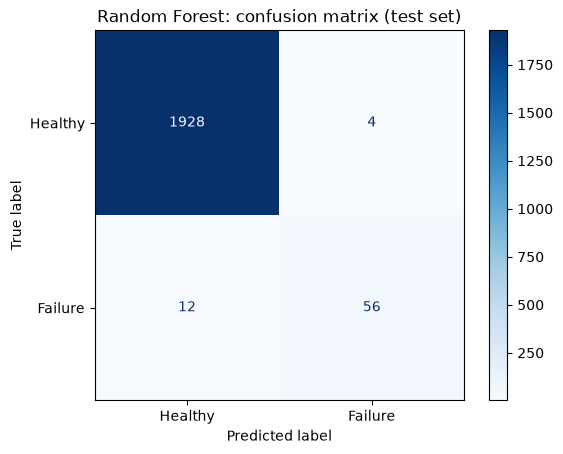

Failures caught : 56
Failures missed : 12
False alarms    : 4


In [9]:
cm = confusion_matrix(y_test, test_pred)
ConfusionMatrixDisplay(cm, display_labels=["Healthy", "Failure"]).plot(cmap="Blues")
plt.title(f"{best_name}: confusion matrix (test set)")
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"Failures caught : {tp}")
print(f"Failures missed : {fn}")
print(f"False alarms    : {fp}")

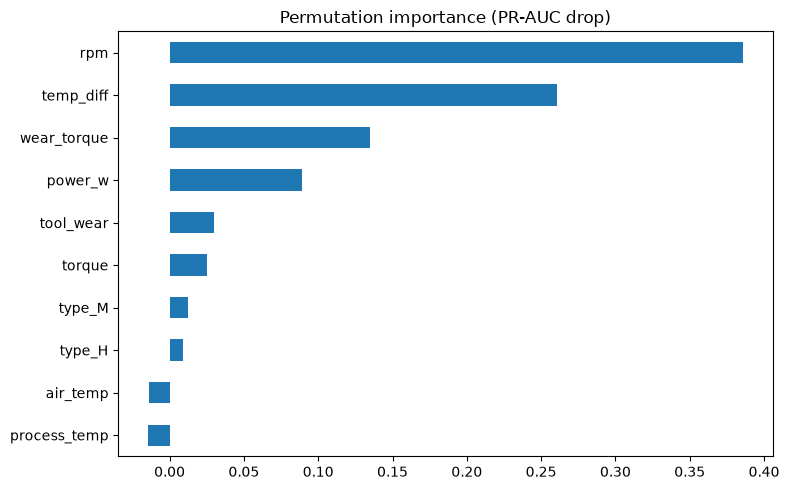

In [10]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(
    final_model, X_test, y_test,
    scoring="average_precision", n_repeats=10, random_state=42,
)
importance = pd.Series(perm.importances_mean, index=X_test.columns).sort_values()

importance.plot.barh(figsize=(8, 5), title="Permutation importance (PR-AUC drop)")
plt.tight_layout()
plt.show()

In [11]:
import joblib
from pathlib import Path

Path("../models").mkdir(exist_ok=True)

artifact = {
    "model": final_model,
    "threshold": threshold,
    "feature_columns": FEATURE_COLUMNS,
    "model_name": best_name,
}
joblib.dump(artifact, "../models/failure_model.joblib")

# Quick reload test
loaded = joblib.load("../models/failure_model.joblib")
print("Saved and reloaded OK:", loaded["model_name"], "| threshold:", round(loaded["threshold"], 3))
print("Sample risk scores:", loaded["model"].predict_proba(X_test.head(3))[:, 1].round(3))

Saved and reloaded OK: Random Forest | threshold: 0.485
Sample risk scores: [0.075 0.    0.164]
